<a href="https://colab.research.google.com/github/SamiNt67/Digitalizaci-n-proyecto/blob/main/Pr%C3%A1ctica1_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
1. Crear el modelo en Teachable Machine
Paso 1. Entrar en la página oficial:

Teachable Machine

Paso 2. Pulsar en Primeros Pasos (Get Started).

Paso 3. Seleccionar Proyecto de imagen (Image Project).

Paso 4. Eligir Modelo de imagen estándar (Standard image model).

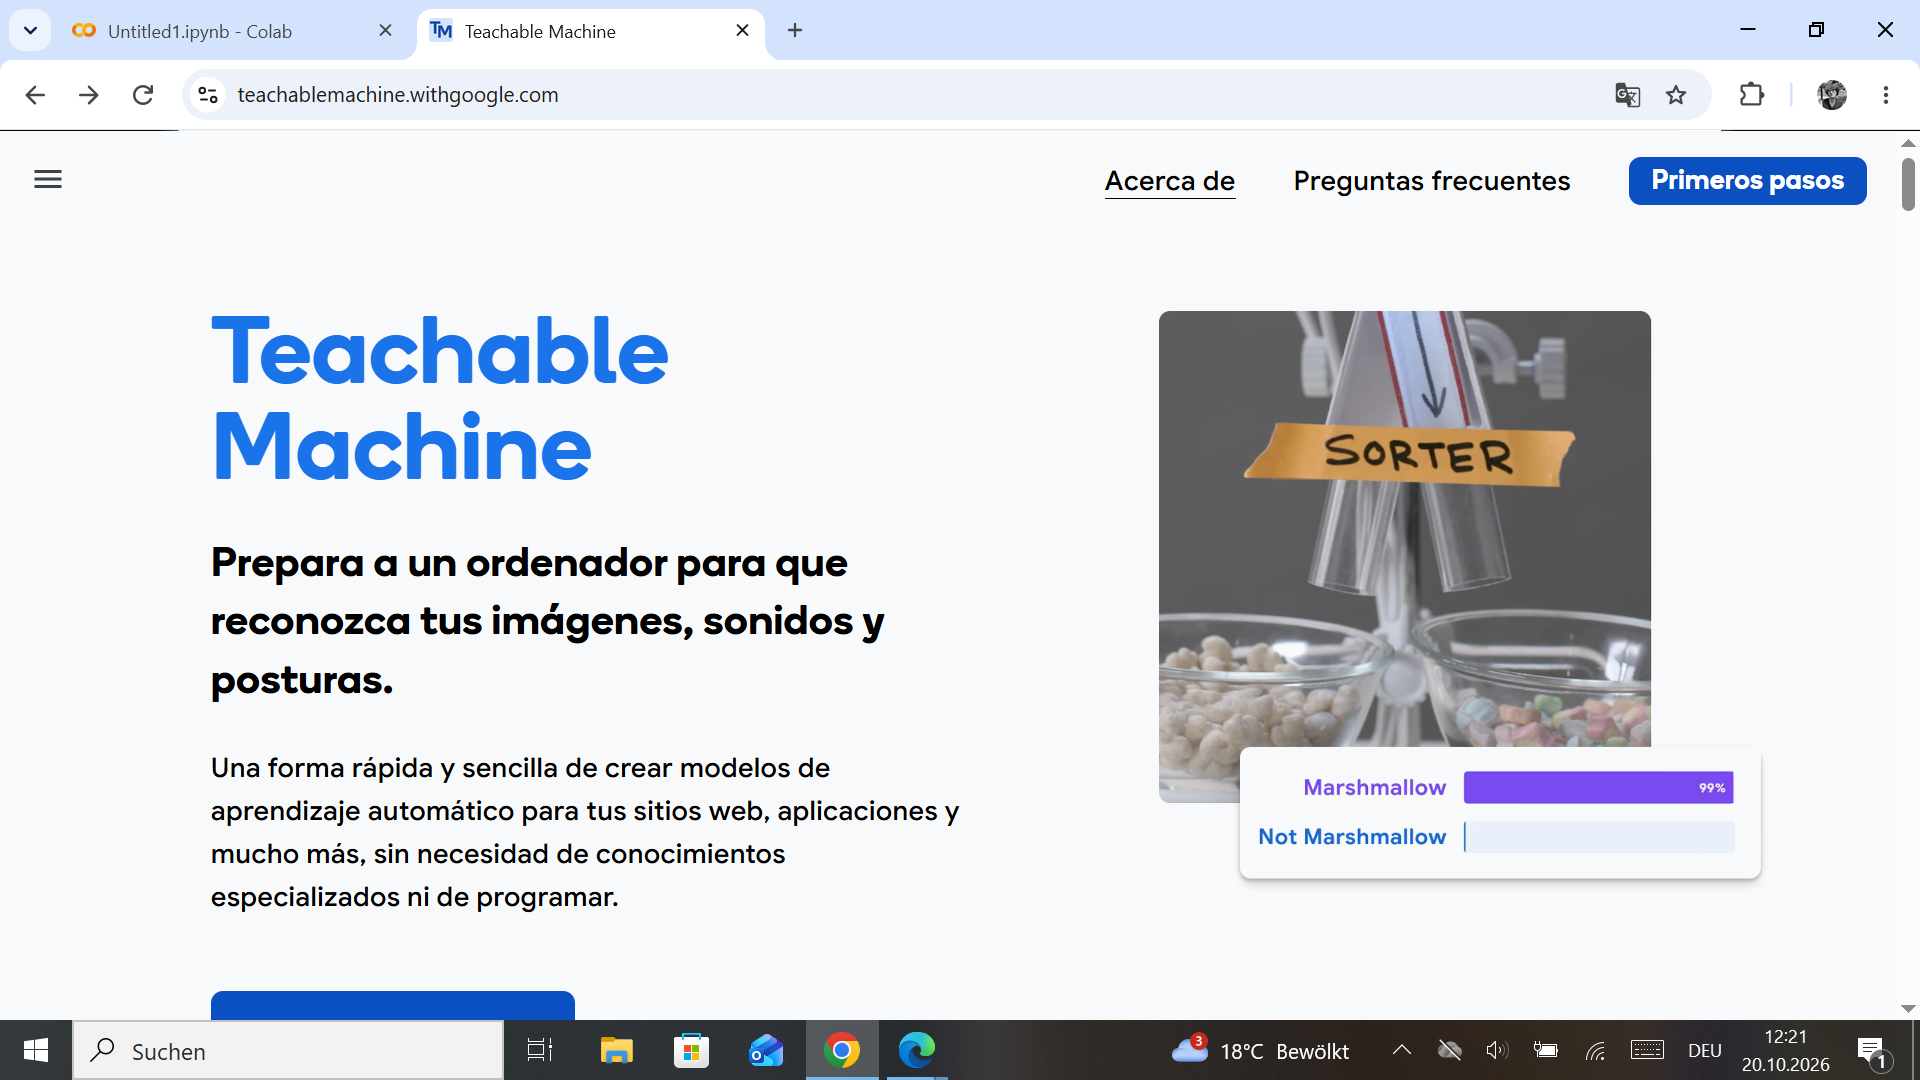

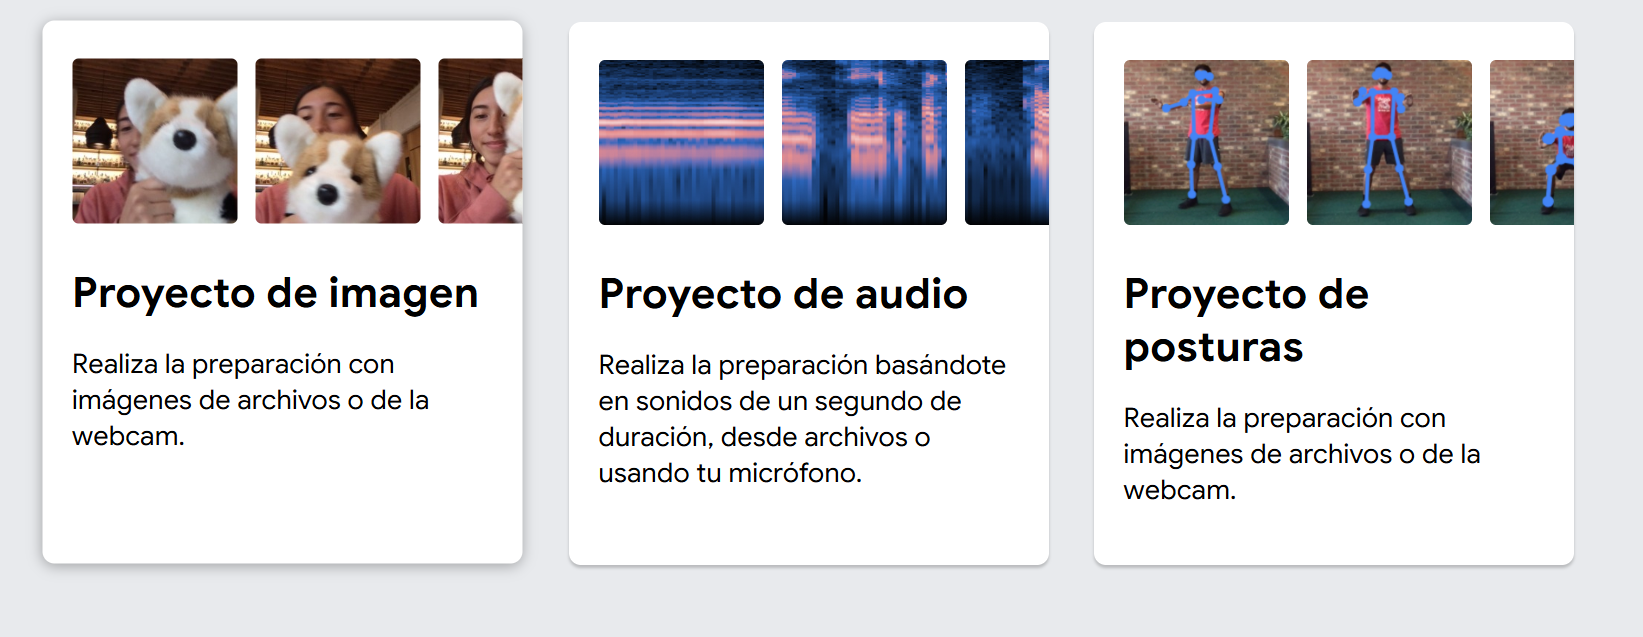

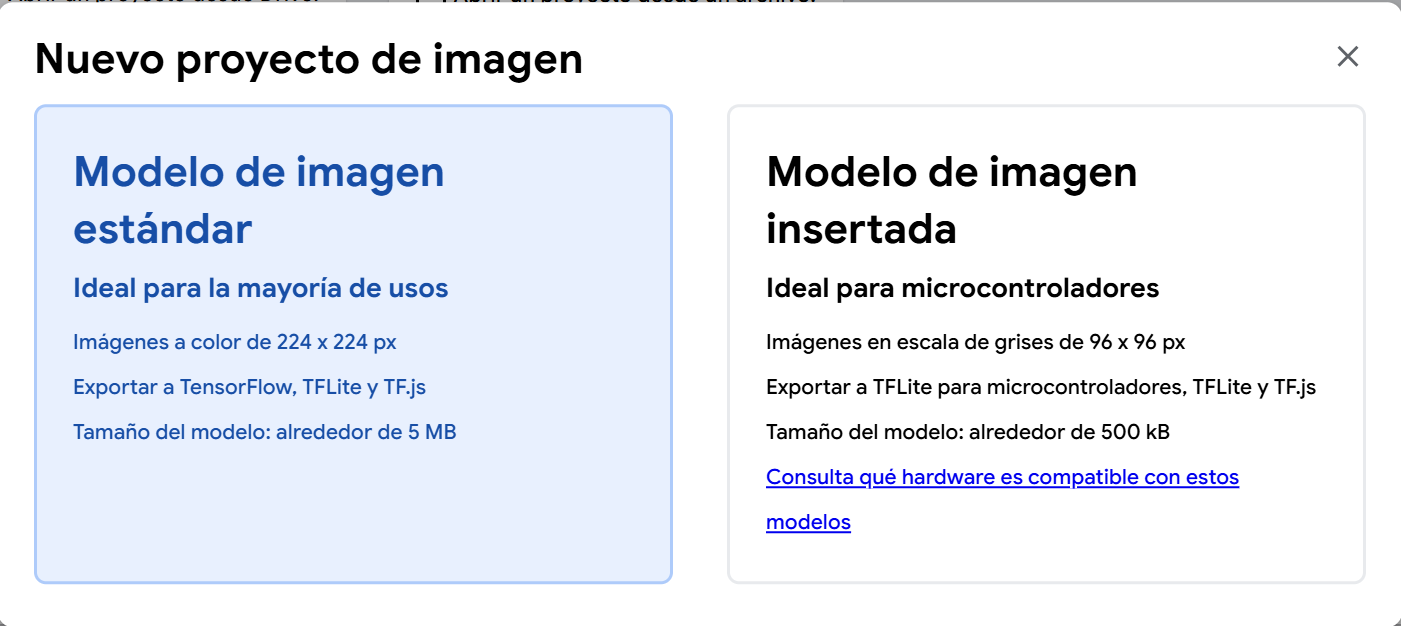

In [ ]:
2. Crear las dos categorías de imágenes
Cuando se entre en el proyecto, se verá unas clases de ejemplo llamadas Class 1 y Class 2.

Sigue estos pasos:

Cambia el nombre de Class 1 por Libreta.

Cambia el nombre de Class 2 por Móvil.

Se recogen imágenes para cada categoría.

Esto se hace con la webcam: vamos mostrando distintas imágenes de un móvil y una libreta por clase.

También se puede subir imágenes: selecciona imágenes que tengas guardadas en el ordenador.


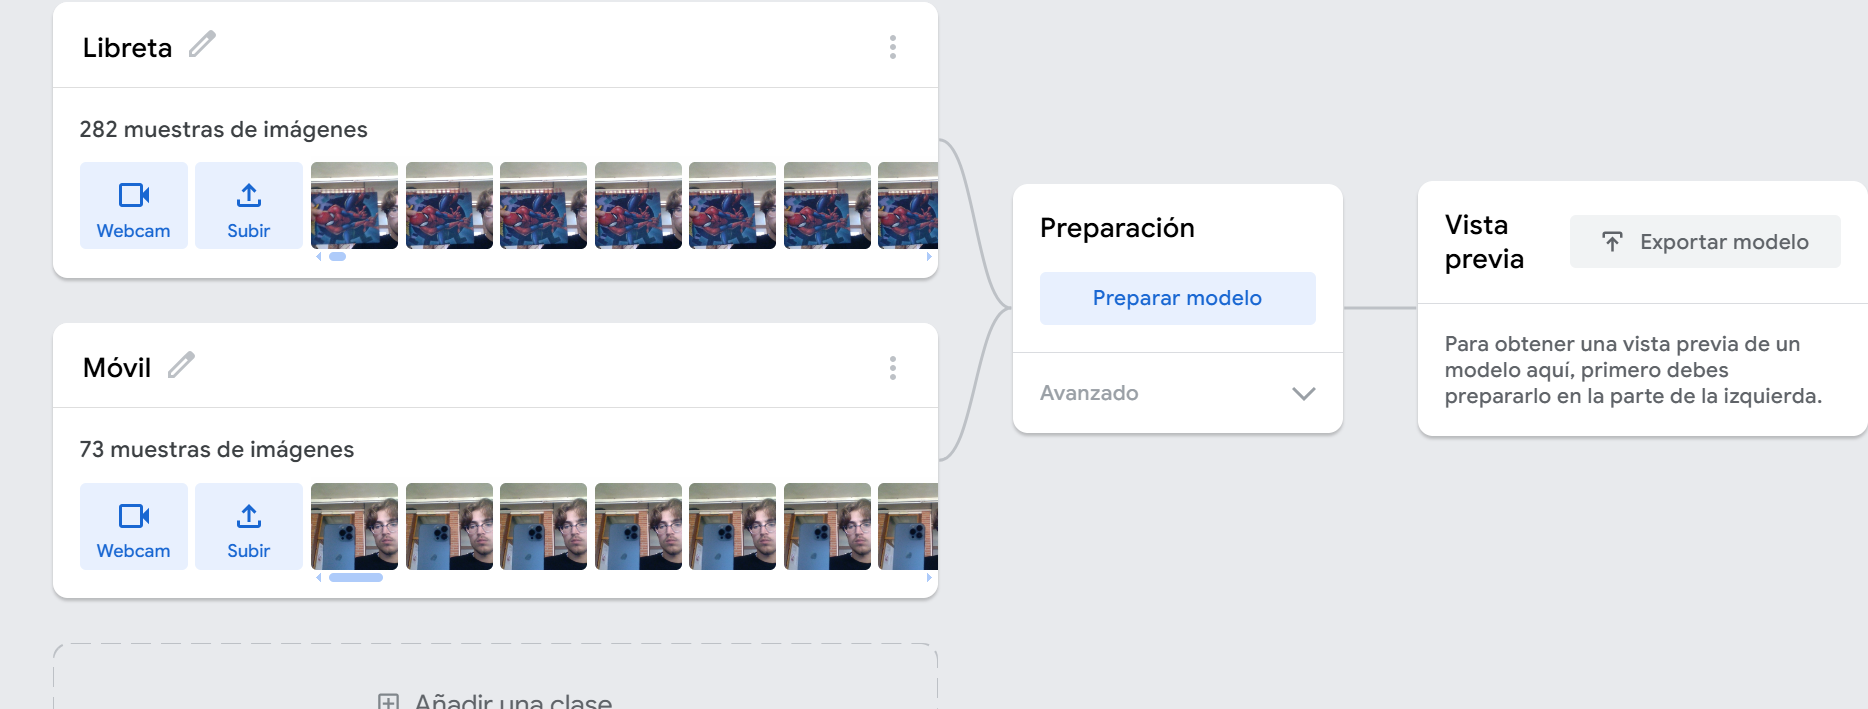

3. Entrenar el modelo
Cuando tenga las dos categorías con sus imágenes:

Buscar el botón preparar modelo (Train Model).

Esperar a que termine el entrenamiento.

Probar el modelo con imágenes nuevas en la sección de vista previa.

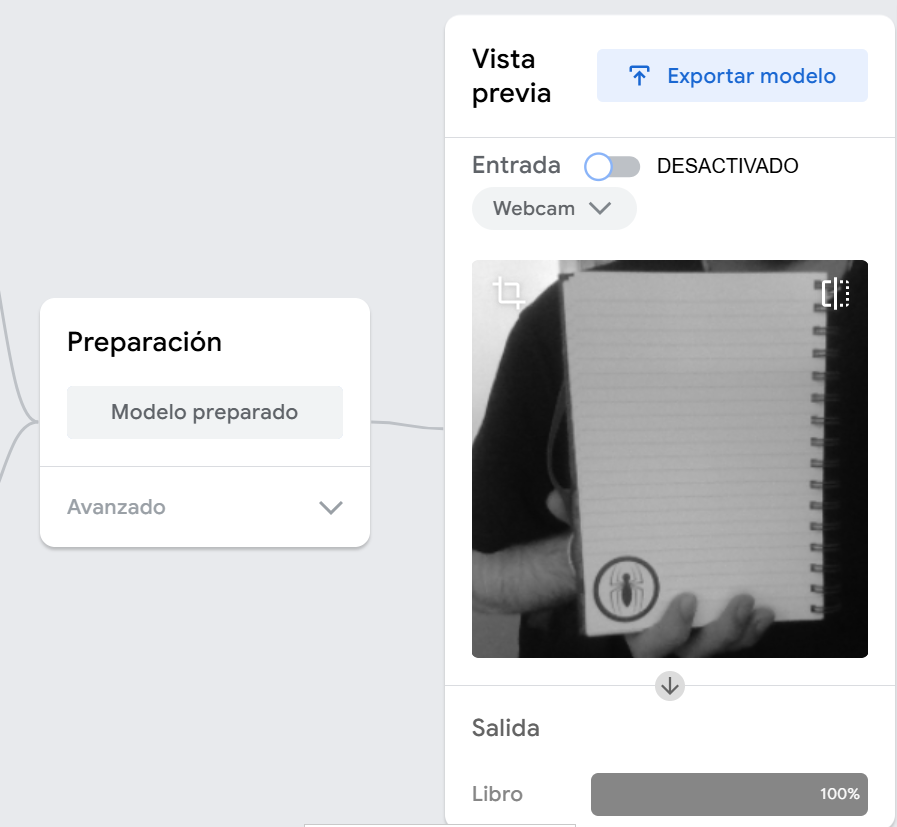

4. Exportar y guardar el modelo

Una vez entrenado, hay que pulsar Exportar modelo (Export Model).

Seleccionar TensorFlow.js.

Eligir la opción de descargar el modelo:

Download: descarga los archivos del modelo para usarlos localmente.



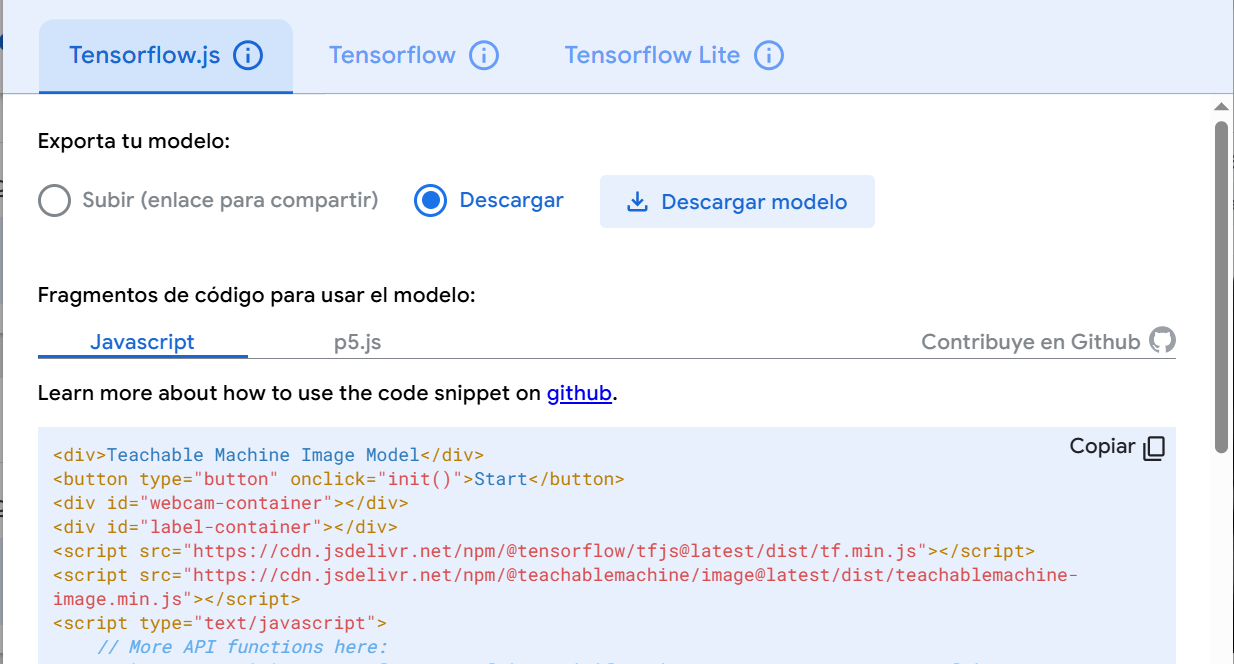

La aplicación clasificadora de imágenes:

 Se creó la carpeta clasificador-imagenes dentro de ModeloIA, con esta estrcutura:

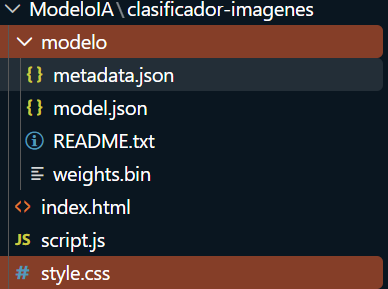

Dentro del Index.html encontramos el siguiente código:

In [ ]:
<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <meta name="theme-color" content="#f1f5f9">
  <title>Clasificador inteligente de imágenes</title>
  <link rel="stylesheet" href="style.css">
  <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
  <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
  <script src="script.js" defer></script>
</head>
<body>
  <main class="contenedor">
    <header>
      <p class="etiqueta">INTELIGENCIA ARTIFICIAL</p>
      <h1>Clasificador de imágenes</h1>
      <p>Analiza imágenes con tu modelo de inteligencia artificial.</p>
    </header>

    <p id="estado" class="estado" role="status" aria-live="polite">Preparado. Carga tu modelo para comenzar.</p>

    <section class="panel" aria-labelledby="tituloCamara">
      <h2 id="tituloCamara">Cámara</h2>
      <p>Inicia la cámara para clasificar imágenes en tiempo real.</p>
      <div class="botones">
        <button id="iniciar" type="button">Iniciar cámara</button>
        <button id="detener" type="button" class="boton-secundario" disabled>Detener cámara</button>
      </div>
      <div id="camara" class="visor" aria-label="Vista de la cámara">
        <p>La vista de la cámara aparecerá aquí.</p>
      </div>
    </section>

    <section class="panel" aria-labelledby="tituloConfiguracion">
      <h2 id="tituloConfiguracion">Configuración</h2>
      <label for="umbral">Umbral mínimo de confianza: <output id="valorUmbral" for="umbral">70%</output></label>
      <input id="umbral" type="range" min="0" max="100" value="70">
      <label for="mensajePersonalizado">Mensaje cuando hay coincidencia</label>
      <input id="mensajePersonalizado" type="text" maxlength="120" placeholder="Ej.: ¡Objeto identificado!">
    </section>

    <section class="panel" aria-labelledby="tituloImagen">
      <h2 id="tituloImagen">Clasificar una imagen</h2>
      <label for="archivo">Selecciona una imagen</label>
      <input id="archivo" type="file" accept="image/*">
      <img id="imagenSubida" alt="Vista previa de la imagen seleccionada" hidden>
      <div class="botones">
        <button id="clasificarArchivo" type="button" disabled>Clasificar imagen</button>
      </div>
      <p id="resultadoArchivo" class="texto-secundario" role="status" aria-live="polite"></p>
    </section>

    <section class="panel" aria-labelledby="tituloResultados">
      <h2 id="tituloResultados">Resultados</h2>
      <div id="resultados" aria-live="polite">
        <p class="texto-secundario">Las probabilidades aparecerán aquí.</p>
      </div>
      <p id="mensaje" role="status" aria-live="polite"></p>
    </section>

    <section class="panel" aria-labelledby="tituloHistorico">
      <div class="encabezado-historico">
        <h2 id="tituloHistorico">Histórico</h2>
        <button id="limpiar" type="button" class="boton-secundario">Borrar histórico</button>
      </div>
      <ol id="historico"></ol>
      <p id="historicoVacio" class="texto-secundario">Todavía no hay clasificaciones guardadas.</p>
    </section>

    <footer>
      <p>La cámara requiere permiso y una conexión segura o un servidor local (por ejemplo, Live Server).</p>
    </footer>
  </main>
</body>
</html>


Dentro del script.js encontramos el siguiente código:

In [ ]:
"use strict";

const URL_MODELO = "./modelo/";
const MAX_REGISTROS = 50;
const INTERVALO_HISTORIAL_CAMARA = 2000;

let modelo = null;
let webcam = null;
let ejecutando = false;
let procesando = false;
let ultimaEntradaCamara = 0;
let ultimaImagen = null;
let historial = cargarHistorial();

const $ = (id) => document.getElementById(id);
const botonIniciar = $("iniciar");
const botonDetener = $("detener");
const estado = $("estado");
const resultados = $("resultados");
const mensaje = $("mensaje");
const umbral = $("umbral");
const valorUmbral = $("valorUmbral");
const historico = $("historico");
const historicoVacio = $("historicoVacio");
const imagenSubida = $("imagenSubida");
const botonClasificarArchivo = $("clasificarArchivo");

function cargarHistorial() {
  try {
    const guardado = JSON.parse(localStorage.getItem("historialClasificador") || "[]");
    return Array.isArray(guardado) ? guardado.slice(0, MAX_REGISTROS) : [];
  } catch (error) {
    console.error("No se pudo leer el histórico guardado:", error);
    return [];
  }
}

function guardarHistorial(origen, nombre, predicciones) {
  const minimo = Number(umbral.value) / 100;
  const mejor = [...predicciones].sort((a, b) => b.probability - a.probability)[0];
  const coincide = mejor && mejor.probability >= minimo;
  const registro = {
    fecha: new Date().toLocaleString("es-ES"),
    origen,
    nombre,
    clase: coincide ? mejor.className : "Sin coincidencia",
    confianza: mejor ? Math.round(mejor.probability * 100) : 0
  };

  historial.unshift(registro);
  historial = historial.slice(0, MAX_REGISTROS);
  try {
    localStorage.setItem("historialClasificador", JSON.stringify(historial));
  } catch (error) {
    console.error("No se pudo guardar el histórico:", error);
    estado.textContent = "Clasificación completada, pero no se pudo guardar el histórico.";
  }
  mostrarHistorial();
}

function mostrarHistorial() {
  historico.replaceChildren();
  historial.forEach((registro) => {
    const elemento = document.createElement("li");
    elemento.textContent =
      `${registro.fecha} — ${registro.origen}: ${registro.nombre} — ` +
      `${registro.clase} (${registro.confianza}%)`;
    historico.appendChild(elemento);
  });
  historicoVacio.hidden = historial.length > 0;
}

function mostrarPredicciones(predicciones, nombre, origen) {
  resultados.replaceChildren();
  const minimo = Number(umbral.value) / 100;
  const ordenadas = [...predicciones].sort((a, b) => b.probability - a.probability);

  ordenadas.forEach((prediccion) => {
    const elemento = document.createElement("p");
    elemento.textContent =
      `${prediccion.className}: ${(prediccion.probability * 100).toFixed(1)}%`;
    resultados.appendChild(elemento);
  });

  const mejor = ordenadas[0];
  if (mejor && mejor.probability >= minimo) {
    mensaje.textContent =
      $("mensajePersonalizado").value.trim() || `¡Coincidencia: ${mejor.className}!`;
  } else {
    mensaje.textContent = "No hay ninguna coincidencia que supere el mínimo establecido.";
  }

  if (origen !== "Cámara" || Date.now() - ultimaEntradaCamara >= INTERVALO_HISTORIAL_CAMARA) {
    guardarHistorial(origen, nombre, ordenadas);
    if (origen === "Cámara") ultimaEntradaCamara = Date.now();
  }
}

async function cargarModelo() {
  if (modelo) return modelo;
  estado.textContent = "Cargando modelo de inteligencia artificial...";
  try {
    modelo = await tmImage.load(
      `${URL_MODELO}model.json`,
      `${URL_MODELO}metadata.json`
    );
    estado.textContent = "Modelo cargado correctamente.";
    return modelo;
  } catch (error) {
    estado.textContent =
      "No se pudo cargar el modelo. Comprueba que modelo/model.json y metadata.json estén en la carpeta.";
    console.error("Error al cargar el modelo:", error);
    throw error;
  }
}

async function iniciarCamara() {
  if (ejecutando) return;
  botonIniciar.disabled = true;
  estado.textContent = "Preparando cámara...";

  try {
    await cargarModelo();
    webcam = new tmImage.Webcam(320, 320, true);
    await webcam.setup();
    await webcam.play();
    $("camara").replaceChildren(webcam.canvas);
    ejecutando = true;
    botonDetener.disabled = false;
    estado.textContent = "Cámara activa. Analizando imágenes...";
    requestAnimationFrame(buclePredicciones);
  } catch (error) {
    if (webcam) webcam.stop();
    webcam = null;
    ejecutando = false;
    botonIniciar.disabled = false;
    botonDetener.disabled = true;
    if (!estado.textContent.startsWith("No se pudo cargar el modelo.")) {
      estado.textContent =
        "No se pudo iniciar la cámara. Comprueba los permisos y que la página se sirva por HTTP.";
    }
    console.error("No se pudo iniciar la cámara:", error);
  }
}

async function buclePredicciones() {
  if (!ejecutando || !webcam || procesando) return;
  procesando = true;
  try {
    webcam.update();
    const predicciones = await modelo.predict(webcam.canvas);
    if (ejecutando) mostrarPredicciones(predicciones, "Cámara web", "Cámara");
  } catch (error) {
    console.error("Error al clasificar:", error);
    estado.textContent = "Error al analizar la imagen.";
  } finally {
    procesando = false;
  }

  if (ejecutando) requestAnimationFrame(buclePredicciones);
}

function detenerCamara() {
  ejecutando = false;
  if (webcam) {
    webcam.stop();
    webcam = null;
  }
  $("camara").replaceChildren(Object.assign(document.createElement("p"), {
    textContent: "La vista de la cámara aparecerá aquí."
  }));
  botonIniciar.disabled = false;
  botonDetener.disabled = true;
  estado.textContent = "Cámara detenida.";
}

async function seleccionarImagen(evento) {
  const archivo = evento.target.files[0];
  botonClasificarArchivo.disabled = true;
  if (!archivo) return;
  if (!archivo.type.startsWith("image/")) {
    estado.textContent = "Selecciona un archivo de imagen válido.";
    imagenSubida.hidden = true;
    return;
  }

  if (ultimaImagen) URL.revokeObjectURL(ultimaImagen);
  ultimaImagen = URL.createObjectURL(archivo);
  try {
    const cargaImagen = new Promise((resolve, reject) => {
      imagenSubida.onload = resolve;
      imagenSubida.onerror = reject;
    });
    imagenSubida.src = ultimaImagen;
    imagenSubida.hidden = false;
    await cargaImagen;
    estado.textContent = `Imagen cargada: ${archivo.name}`;
    botonClasificarArchivo.disabled = false;
  } catch (error) {
    estado.textContent = "No se pudo abrir la imagen seleccionada.";
    console.error("Error al cargar la imagen:", error);
  }
}

async function clasificarImagenSubida() {
  if (!imagenSubida.src || imagenSubida.hidden) {
    $("resultadoArchivo").textContent = "Primero selecciona una imagen.";
    return;
  }

  botonClasificarArchivo.disabled = true;
  try {
    await cargarModelo();
    const predicciones = await modelo.predict(imagenSubida);
    mostrarPredicciones(
      predicciones,
      $("archivo").files[0]?.name || "Imagen subida",
      "Archivo"
    );
    $("resultadoArchivo").textContent =
      "Clasificación completada. Consulta las probabilidades.";
  } catch (error) {
    console.error("No se pudo clasificar la imagen:", error);
    $("resultadoArchivo").textContent =
      "No se pudo clasificar la imagen. Comprueba que el modelo esté instalado.";
  } finally {
    botonClasificarArchivo.disabled = false;
  }
}

umbral.addEventListener("input", () => {
  valorUmbral.value = `${umbral.value}%`;
  valorUmbral.textContent = `${umbral.value}%`;
});
botonIniciar.addEventListener("click", iniciarCamara);
botonDetener.addEventListener("click", detenerCamara);
$("archivo").addEventListener("change", seleccionarImagen);
botonClasificarArchivo.addEventListener("click", clasificarImagenSubida);
$("limpiar").addEventListener("click", () => {
  historial = [];
  localStorage.removeItem("historialClasificador");
  mostrarHistorial();
});

mostrarHistorial();


Dentro del style.css emcontramos el siguiente código:

In [ ]:
* {
  box-sizing: border-box;
}

body {
  margin: 0;
  font-family: Arial, sans-serif;
  background: #f1f5f9;
  color: #172033;
}

.contenedor {
  width: min(100% - 32px, 950px);
  margin: 0 auto;
  padding: 32px 0;
}

header {
  text-align: center;
  padding: 30px 10px;
}

.etiqueta {
  color: #4f46e5;
  font-size: 12px;
  font-weight: bold;
  letter-spacing: 2px;
}

h1 {
  font-size: clamp(28px, 5vw, 44px);
  margin: 12px 0;
}

header > p:last-child,
.texto-secundario,
footer {
  color: #64748b;
}

.estado {
  color: #4338ca;
  font-weight: bold;
  text-align: center;
  margin: 0 0 20px;
}

.panel {
  background: white;
  padding: 24px;
  margin-bottom: 20px;
  border-radius: 18px;
  box-shadow: 0 5px 20px #1720330d;
}

h2 {
  font-size: 20px;
  margin-top: 0;
}

.botones {
  display: flex;
  flex-wrap: wrap;
  gap: 10px;
}

button {
  background: #4f46e5;
  color: white;
  border: none;
  border-radius: 10px;
  padding: 12px 18px;
  font-size: 15px;
  cursor: pointer;
}

button:hover:not(:disabled) {
  background: #3730a3;
}

button:focus-visible,
input:focus-visible {
  outline: 3px solid #a5b4fc;
  outline-offset: 2px;
}

button:disabled {
  opacity: 0.45;
  cursor: not-allowed;
}

button.boton-secundario {
  background: #e2e8f0;
  color: #172033;
}

button.boton-secundario:hover:not(:disabled) {
  background: #cbd5e1;
}

label {
  display: block;
  font-weight: bold;
  margin: 14px 0 8px;
}

input[type="range"],
input[type="text"],
input[type="file"] {
  display: block;
  width: 100%;
  margin: 12px 0 20px;
}

input[type="text"],
input[type="file"] {
  padding: 12px;
  border: 1px solid #cbd5e1;
  border-radius: 10px;
}

.visor {
  min-height: 120px;
  display: grid;
  place-items: center;
  color: #64748b;
  text-align: center;
}

#camara canvas,
#imagenSubida {
  display: block;
  max-width: 100%;
  height: auto;
  margin: 20px auto;
  border-radius: 12px;
}

#imagenSubida[hidden] {
  display: none;
}

#resultados p {
  background: #eef2ff;
  padding: 12px;
  border-radius: 8px;
  margin: 8px 0;
}

#mensaje {
  font-weight: bold;
  color: #4338ca;
}

#historico {
  padding-left: 22px;
}

#historico li {
  margin: 12px 0;
  overflow-wrap: anywhere;
}

.encabezado-historico {
  display: flex;
  align-items: center;
  justify-content: space-between;
  gap: 12px;
}

.encabezado-historico h2 {
  margin-bottom: 0;
}

footer {
  text-align: center;
  font-size: 14px;
  padding: 4px 12px;
}

@media (max-width: 600px) {
  .contenedor {
    width: min(100% - 20px, 950px);
    padding-top: 12px;
  }

  .panel {
    padding: 17px;
    border-radius: 14px;
  }

  .botones button {
    flex: 1 1 130px;
  }

  .encabezado-historico {
    align-items: flex-start;
    flex-direction: column;
  }
}


Estas son las pruebas que le he hecho a la aplicación. Cómo se puede ver en las siguientes capturas funciona sin problema:

Este es el aspecto de la página: 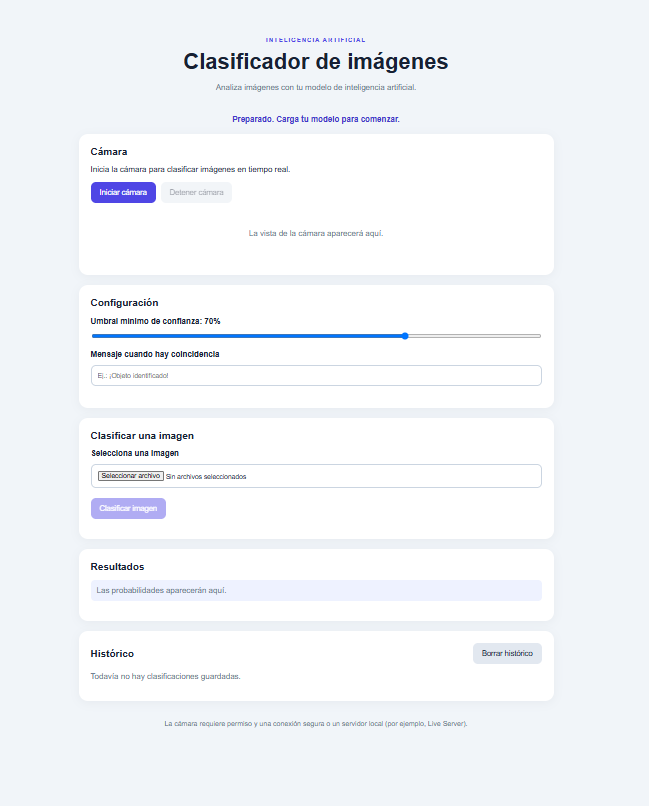

Funciona tanto subiendo la imagen: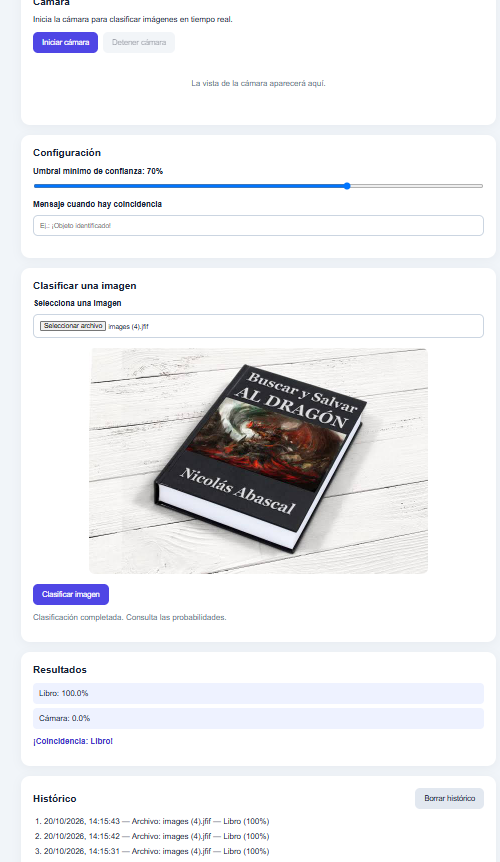

Como usando la cámara para calificar: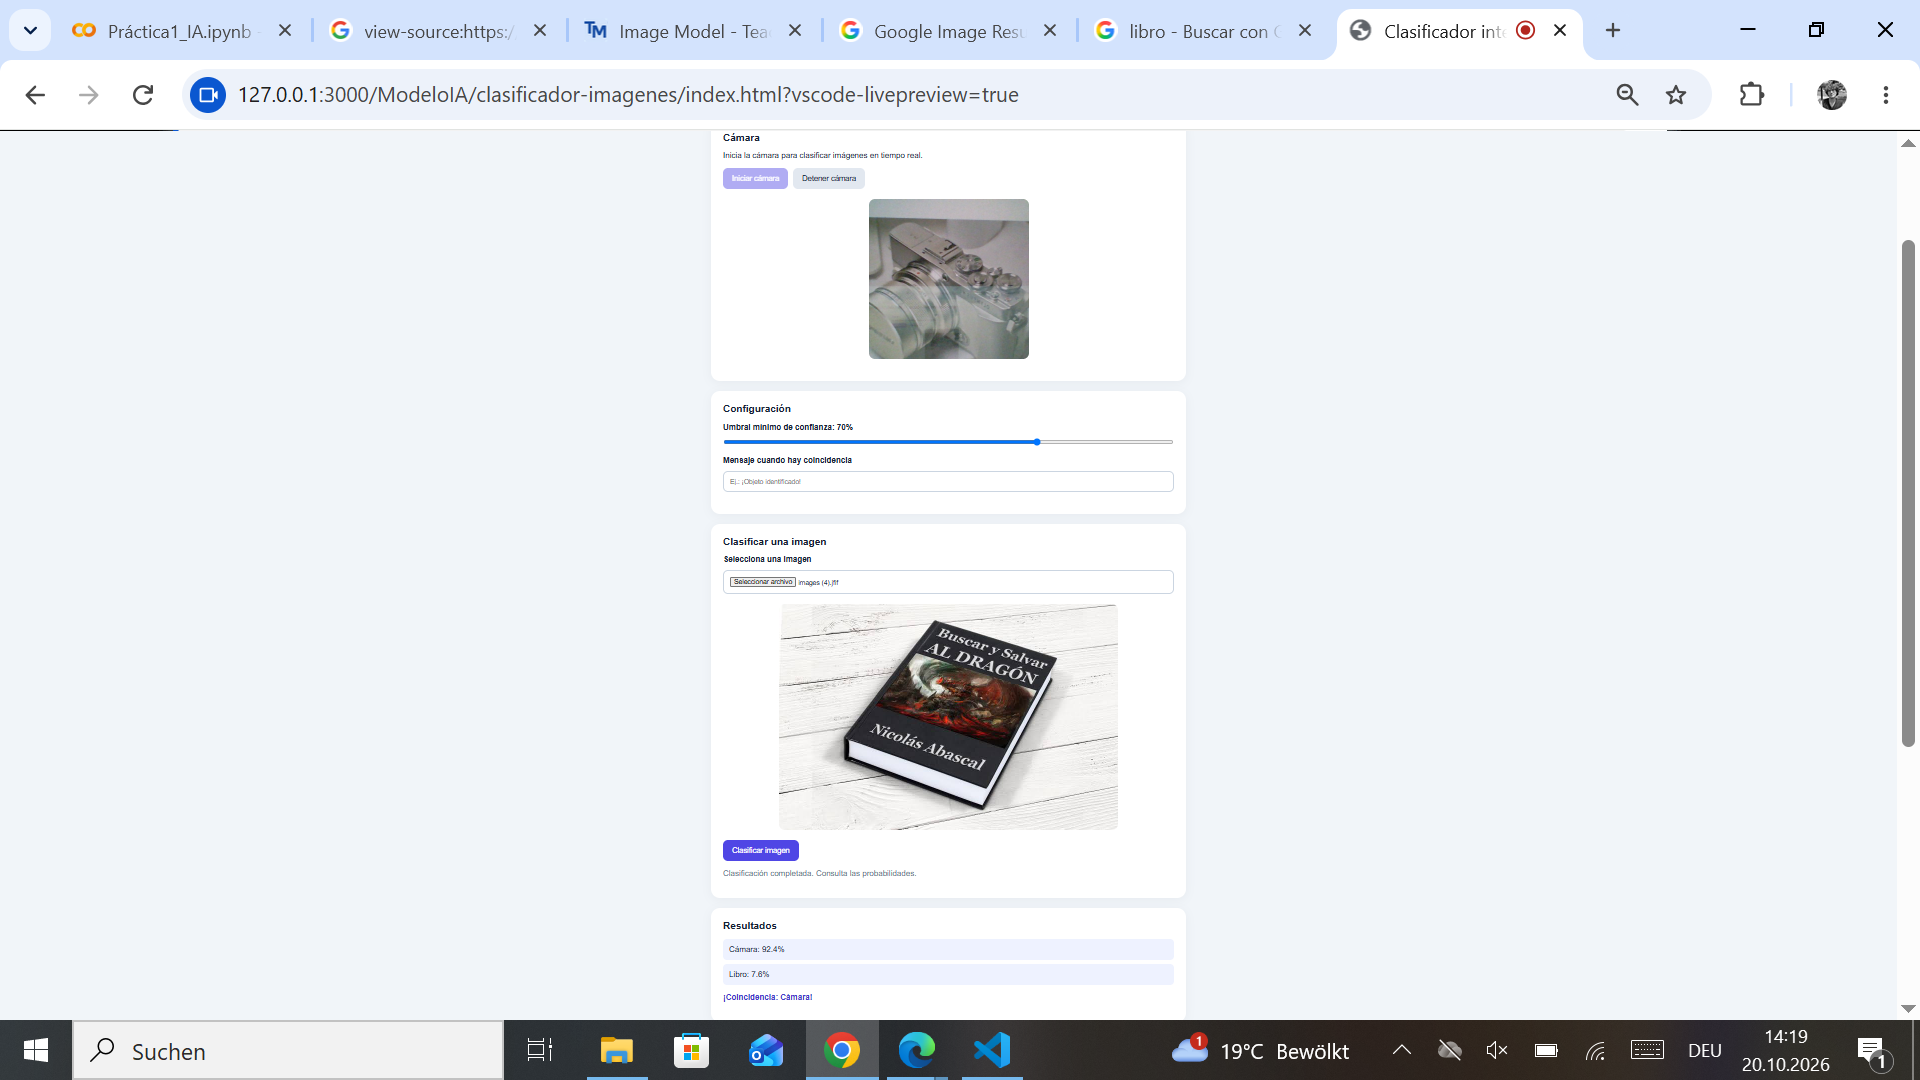

Gracias por leer :)